# Detecção de Fraude em Cartões de Crédito

Este projeto consiste no desenvolvimento e avaliação de modelos de Machine Learning para a classificação e detecção de transações financeiras fraudulentas utilizando técnicas de árvore de decisão (**Decision Tree**) e floresta aleatória (**Random Forest**).

## 📋 Visão Geral do Projeto

A segurança em transações de cartão de crédito é de extrema importância para instituições financeiras e clientes. O objetivo deste notebook é analisar um conjunto de dados de transações reais/simuladas para identificar padrões que caracterizam fraudes e treinar modelos preditivos capazes de sinalizar transações suspeitas com alta acurácia.

## 📊 Base de Dados (`card_transdata.csv`)

O dataset contém as seguintes variáveis:
- **`distance_from_home`**: Distância entre o local da transação e a residência do portador do cartão.
- **`distance_from_last_transaction`**: Distância em relação à última transação realizada.
- **`ratio_to_median_purchase_price`**: Razão do preço da compra atual em relação ao preço médio de compras anteriores.
- **`repeat_retailer`**: Indica se a transação ocorreu em um estabelecimento repetido (frequente).
- **`used_chip`**: Se a transação foi realizada utilizando o chip do cartão.
- **`used_pin_number`**: Se a transação utilizou o número PIN (senha).
- **`online_order`**: Se a compra foi feita de forma online.
- **`fraud`** (Variável Alvo): Indica se a transação é fraudulenta (`1.0`) ou legítima (`0.0`).

## 🛠️ Etapas do Desenvolvimento

1. **Carregamento e Limpeza**: Importação dos dados com Pandas e remoção de registros nulos.
2. **Análise Exploratória (Correlação)**: Visualização da correlação entre as variáveis e o indicador de fraude utilizando um mapa de calor (`seaborn.heatmap`).
3. **Divisão de Dados**: Separação das variáveis explicativas (X) e do alvo (y), seguida da divisão em conjuntos de treino e teste (proporção 80/20) com estratificação.
4. **Modelo de Árvore de Decisão**: Criação, treino e visualização de uma árvore com profundidade máxima limitada (`max_depth=2`).
5. **Modelo de Random Forest**: Treino de um conjunto de árvores de decisão (`n_estimators=5`) para comparar o desempenho e reduzir o sobreajuste.
6. **Avaliação**: Cálculo da acurácia e exportação visual das árvores geradas.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree #visualização da arvore
from sklearn import tree

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import export_graphviz


In [2]:
#subindo a base de dados
dados = pd.read_csv("card_transdata.csv", sep=",")

In [3]:
dados.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


In [4]:
dados.isnull().sum()

,0
distance_from_home,0
distance_from_last_transaction,0
ratio_to_median_purchase_price,0
repeat_retailer,0
used_chip,0
used_pin_number,0
online_order,1
fraud,1


In [5]:
#limpando dados nulos
dados = dados.dropna()

In [6]:
dados.isnull().sum()

,0
distance_from_home,0
distance_from_last_transaction,0
ratio_to_median_purchase_price,0
repeat_retailer,0
used_chip,0
used_pin_number,0
online_order,0
fraud,0


<Axes: >

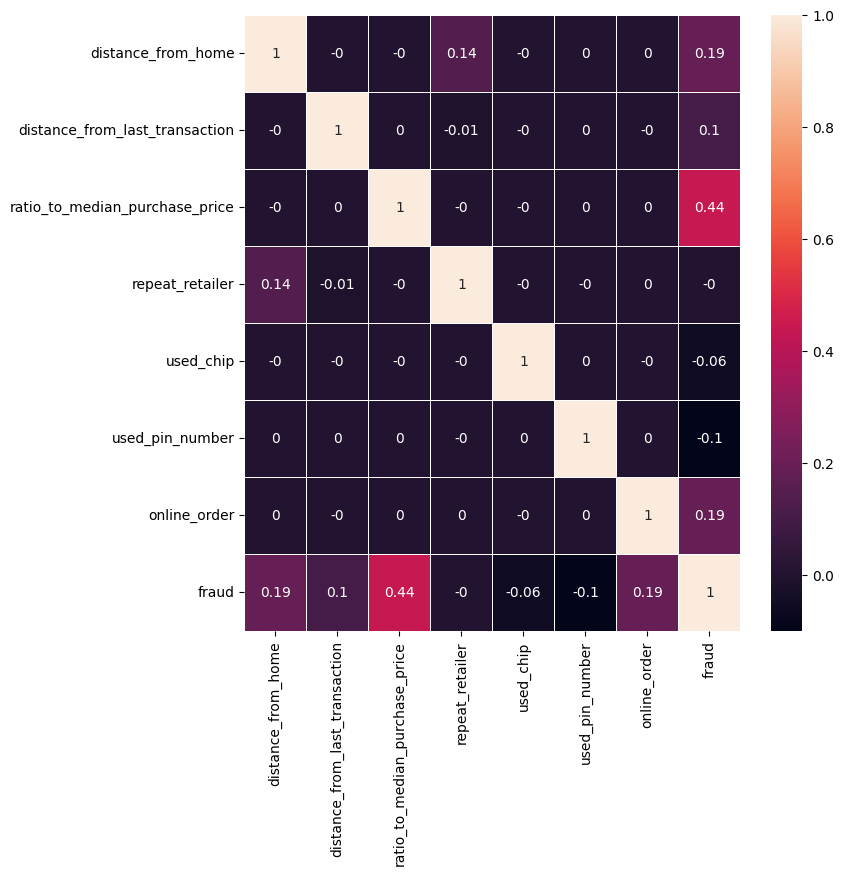

In [7]:
#analisando correlações
correlation_matrix = dados.corr().round(2)

fig, ax = plt.subplots(figsize=(8,8))
sns.heatmap(data=correlation_matrix, annot=True, linewidths=.5, ax=ax)

In [8]:
#Separando os dados
x = dados.drop(columns=['fraud'])
y = dados['fraud'] #O que eu quero prever. (Target)

In [9]:
#Separando em bases de treino e teste
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=7)

# **Criando modelos de árvores:**
 **Decion Tree**

Vamos criar um modelo simples, utilizando todas as variáveis do modelo.

In [10]:
dt = DecisionTreeClassifier(random_state=7, criterion='entropy', max_depth=2)
dt.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=2, random_state=7)

In [11]:
y_predito = dt.predict(x_test)

[Text(0.5, 0.8333333333333334, 'x[2] <= 4.0\nentropy = 0.426\nsamples = 76979\nvalue = [70286, 6693]'),
 Text(0.25, 0.5, 'x[0] <= 100.055\nentropy = 0.172\nsamples = 69115\nvalue = [67342, 1773]'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'entropy = 0.053\nsamples = 65584\nvalue = [65189, 395]'),
 Text(0.375, 0.16666666666666666, 'entropy = 0.965\nsamples = 3531\nvalue = [2153, 1378]'),
 Text(0.75, 0.5, 'x[6] <= 0.5\nentropy = 0.954\nsamples = 7864\nvalue = [2944, 4920]'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'entropy = 0.526\nsamples = 2761\nvalue = [2433, 328]'),
 Text(0.875, 0.16666666666666666, 'entropy = 0.469\nsamples = 5103\nvalue = [511.0, 4592.0]')]

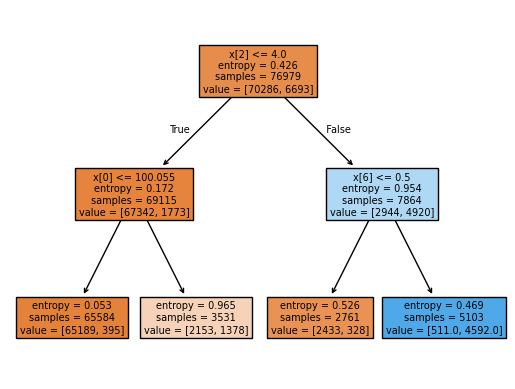

In [12]:
tree.plot_tree(dt, filled=True)

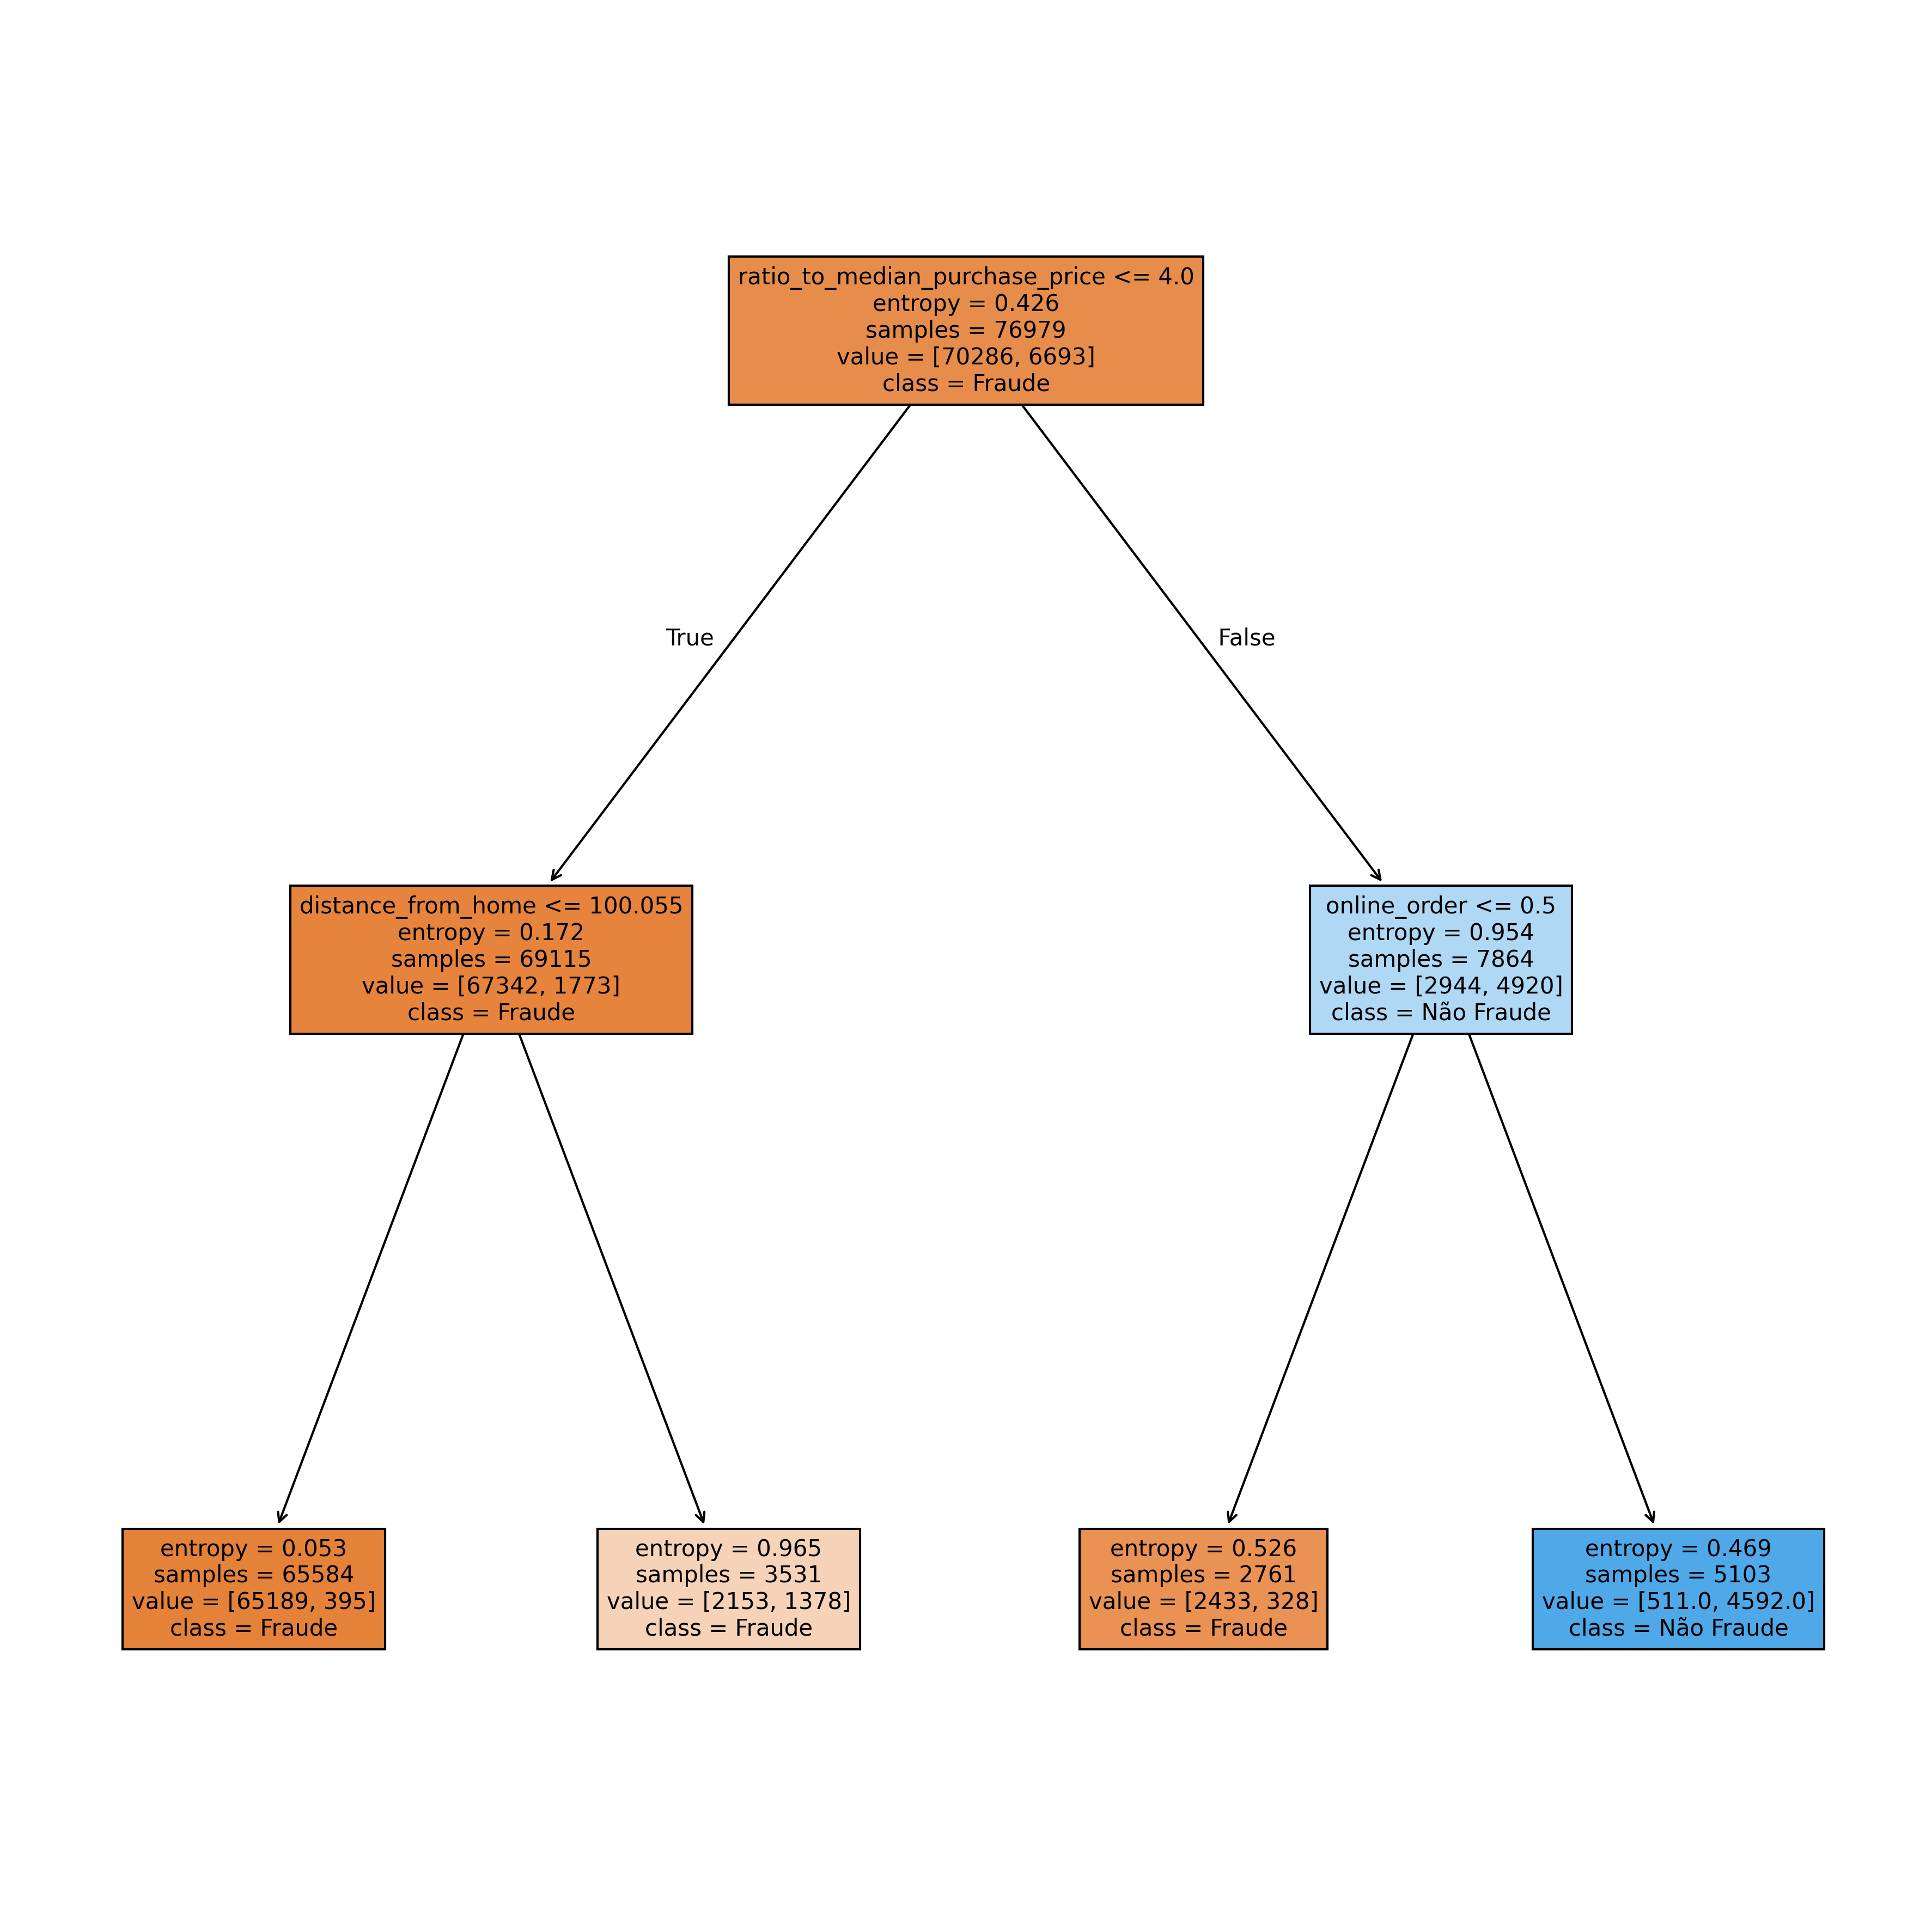

In [13]:
class_names = ['Fraude', 'Não Fraude']
label_names = ['distance_from_home', 'distance_from_last_transaction', 'ratio_to_median_purchase_price', 'repeat_retailer',	'used_chip',	'used_pin_number',	'online_order']

fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (15,15), dpi=300)
tree.plot_tree(dt,
               feature_names = label_names,
               class_names=class_names,
               filled = True)
fig.savefig('dt.png')

In [14]:
#Métricas de predição, revocação, f1-score e acurácia.
print(accuracy_score(y_test, y_predito)) ##relatório de validação de métrica de desempenho.

0.9658612626656274


In [18]:
#RANDOM FOREST
rf = RandomForestClassifier(n_estimators=5, max_depth=2, random_state=7)
rf.fit(x_train, y_train)

RandomForestClassifier(max_depth=2, n_estimators=5, random_state=7)

In [19]:
estimator = rf.estimators_

In [21]:
y_predito_random_forest = rf.predict(x_test)

In [22]:
#Métricas de predição, revocação, f1-score e acurácia.
print(accuracy_score(y_test, y_predito_random_forest)) ##relatório de validação de métrica de desempenho.

0.9536502987789036


In [23]:
class_names = ['Fraude', 'Não Fraude']
label_names = ['distance_from_home', 'distance_from_last_transaction', 'ratio_to_median_purchase_price', 'repeat_retailer',	'used_chip',	'used_pin_number',	'online_order']


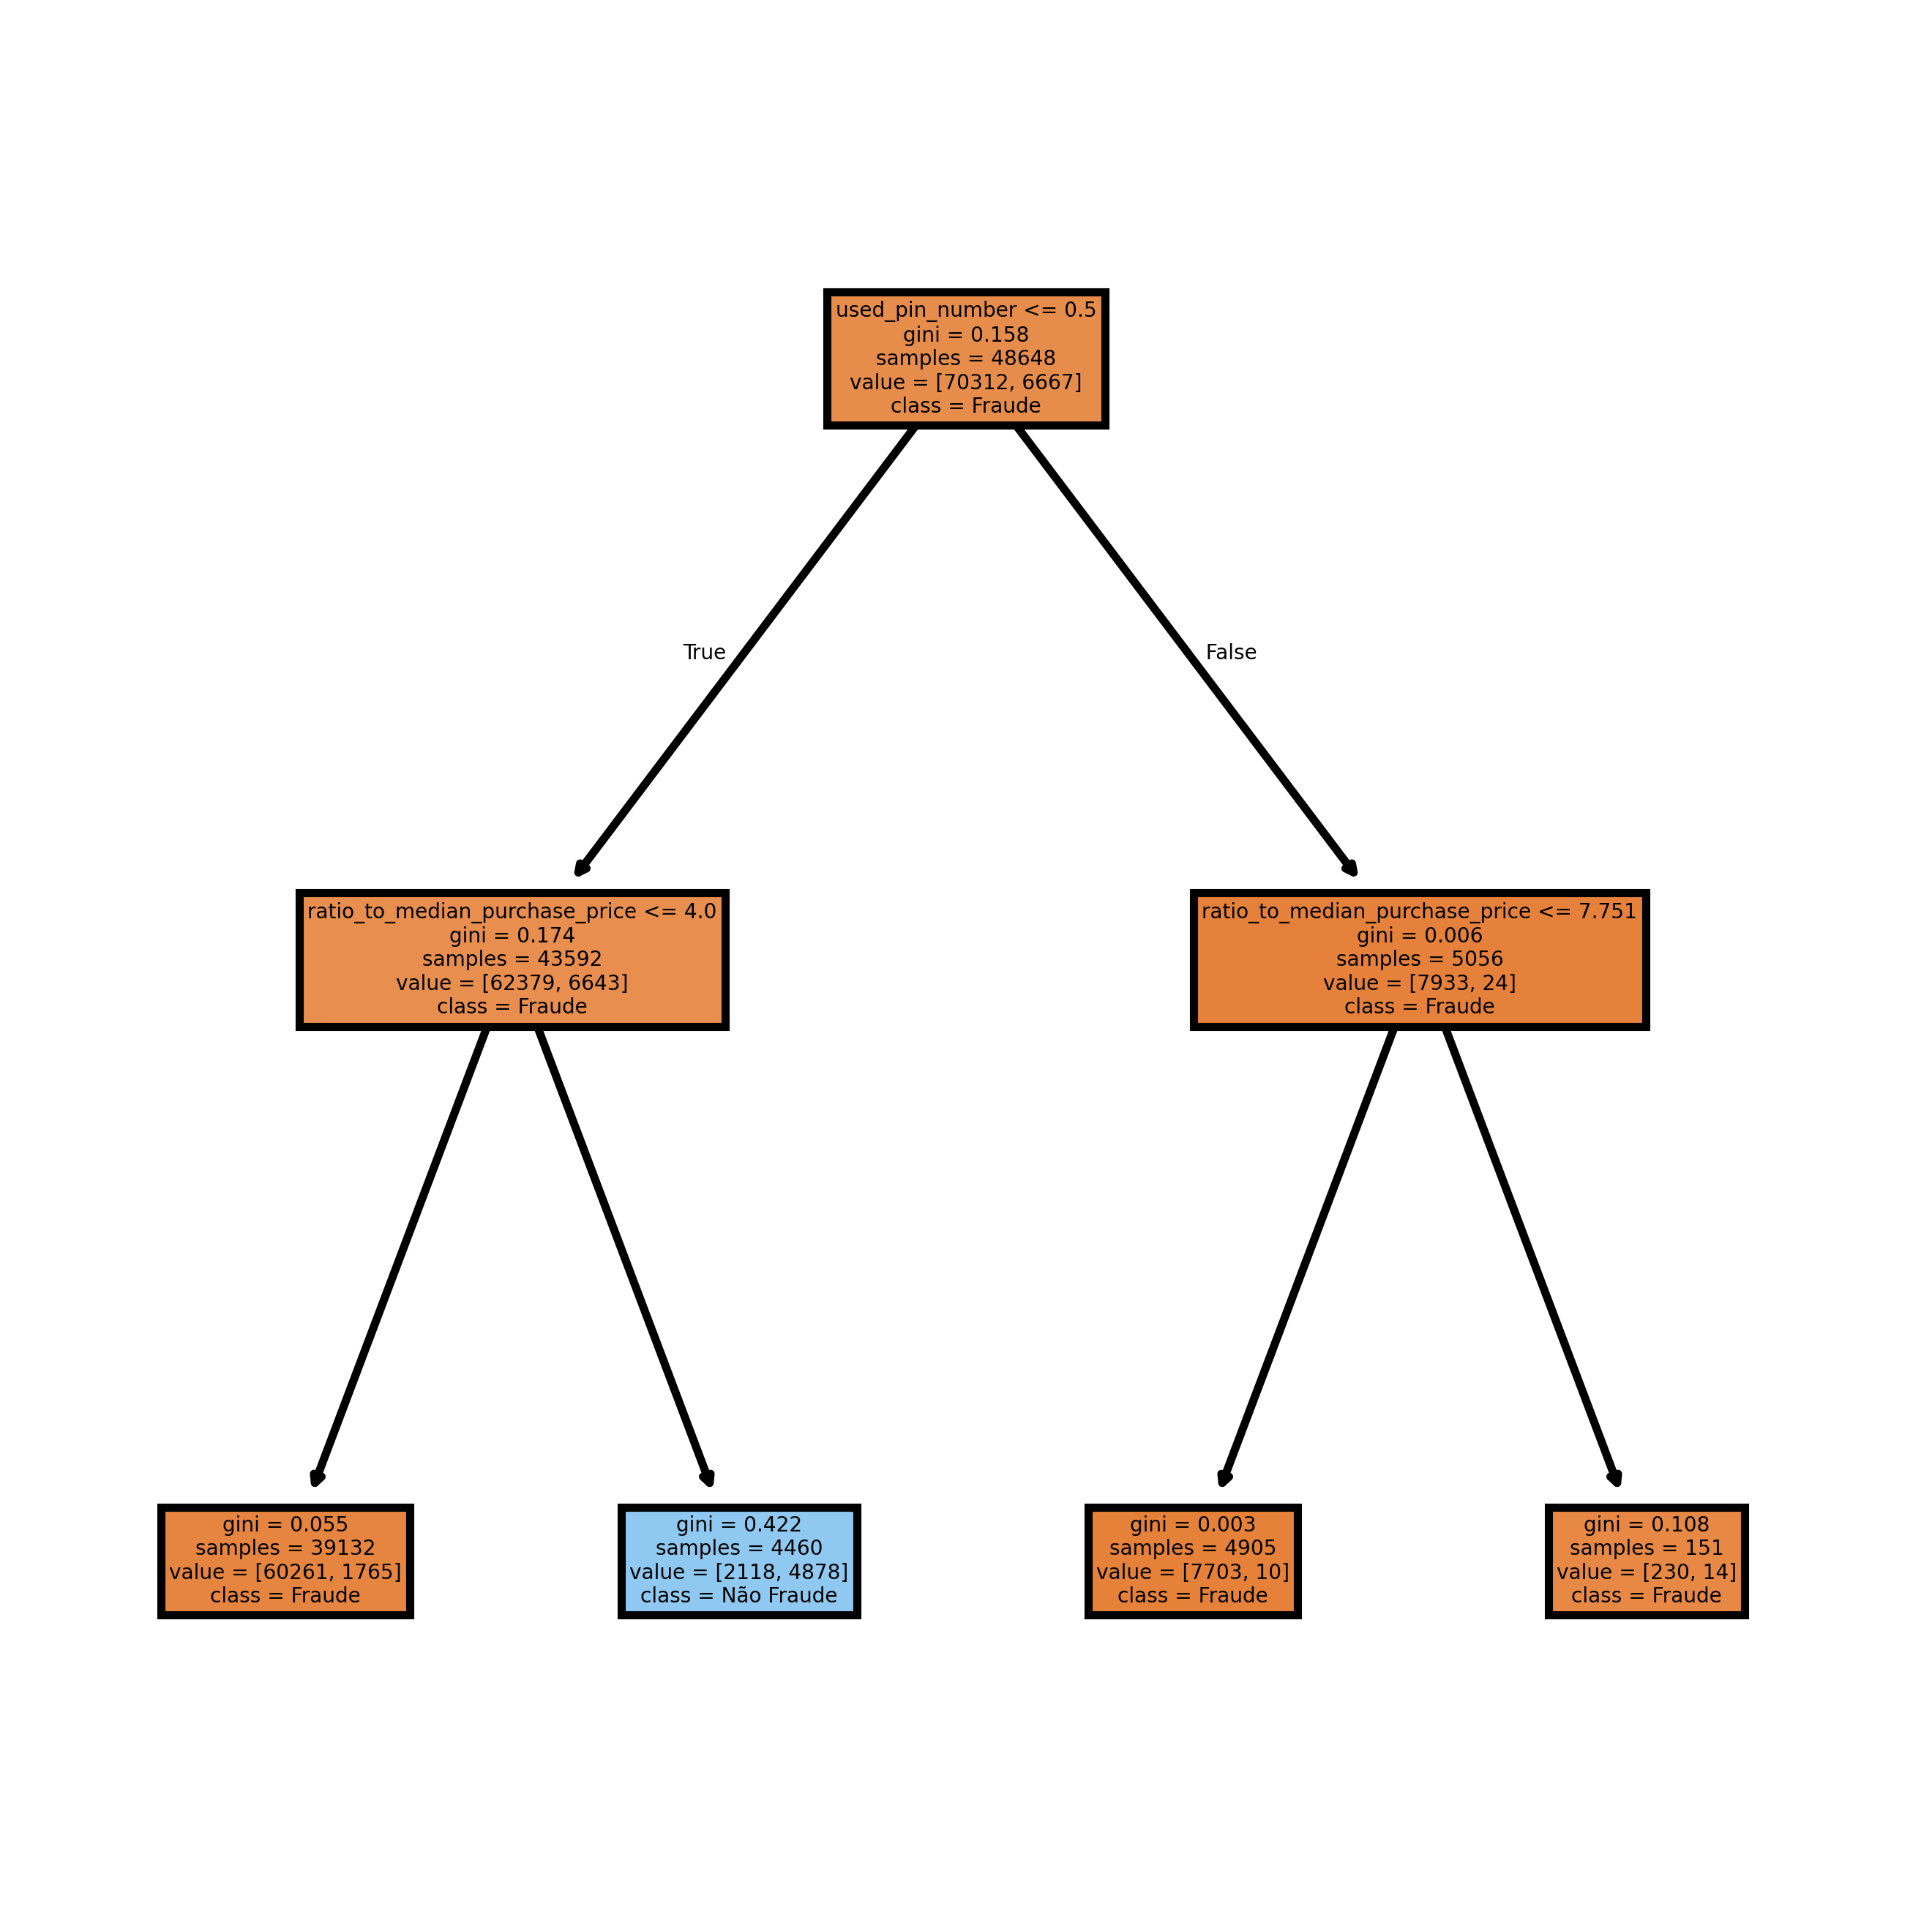

In [24]:
fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (4,4), dpi=800)
tree.plot_tree(estimator[0],
               feature_names = label_names,
               class_names=class_names,
               filled = True)
fig.savefig('dt_random_forest.png')

Plotando todas as árvores geradas:

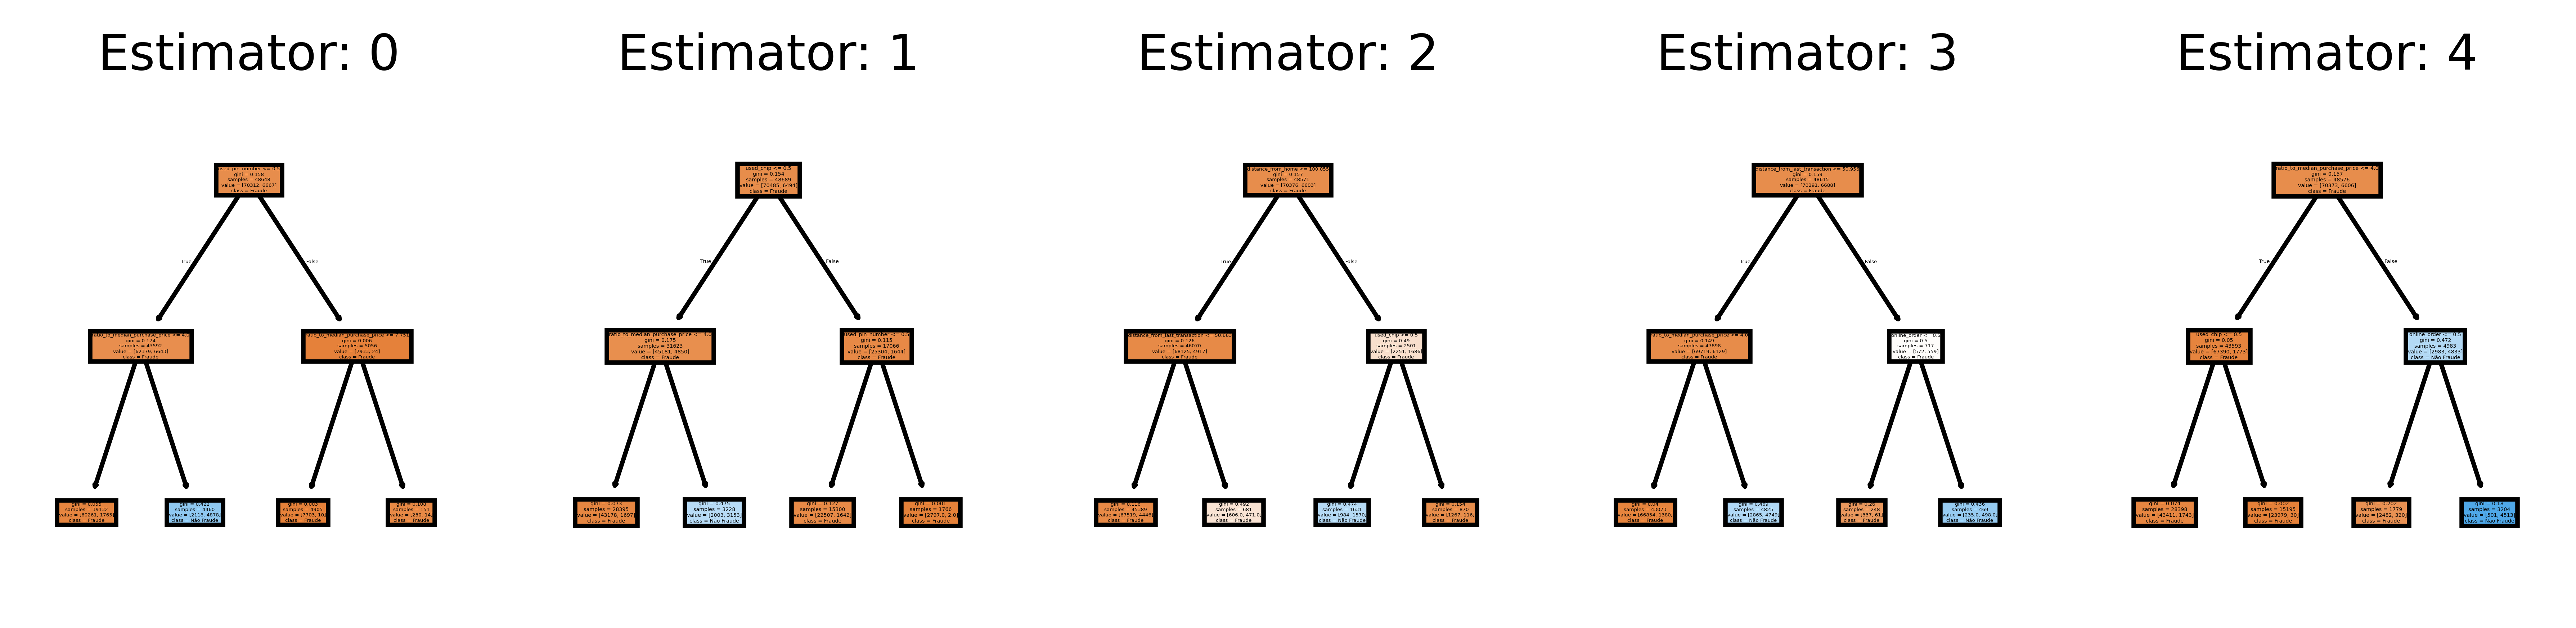

In [25]:
fig, axes = plt.subplots(nrows = 1,ncols = 5, figsize = (10,2), dpi=900)
for index in range(0, 5):
    tree.plot_tree(estimator[index],
                   feature_names = label_names,
                   class_names=class_names,
                   filled = True,
                   ax = axes[index]);

    axes[index].set_title('Estimator: ' + str(index), fontsize = 11)
    fig.savefig('rf_5trees.png')


In [28]:
print (rf.score(x_train, y_train))
print (rf.score(x_test, y_test))
#score da uma visão média da floresta aleatória nos dados fornecidos.

0.9527663388716403
0.9536502987789036
